## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


100%|██████████| 9.91M/9.91M [00:00<00:00, 60.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.73MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 13.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.12MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [3]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Write the interval analysis for the simple model

In [4]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

%pip install bound-propagation

In [5]:
from bound_propagation import BoundModelFactory, HyperRectangle

factory = BoundModelFactory()  #hintsourced

def bounded_mod(y):
    rows = []
    for j in range(10):
        if j != y:
            row = torch.zeros(10)
            row[y] = 1
            row[j] = -1
            rows.append(row)
    last = nn.Linear(10, 9, bias=False)
    last.weight.data = torch.stack(rows)
    net = nn.Sequential(model[1].fc, nn.ReLU(), model[1].fc2, last)
    return factory.build(net)

bounded_models = [bounded_mod(y) for y in range(10)]

In [6]:
def verified_acc(epsilon):
    model.eval()
    verified = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.view(-1, 784)

            low = (images - epsilon).clamp(0, 1)
            high = (images + epsilon).clamp(0, 1)
            low = (low - 0.1307) / 0.3081
            high = (high - 0.1307) / 0.3081
            center = (low + high) / 2
            radius = (high - low) / 2

            for y in range(10):
                mask = labels == y
                if mask.sum() == 0:
                    continue
                bounds_in = HyperRectangle.from_eps(center[mask], radius[mask])  # hintsourced
                bounds_out = bounded_models[y].ibp(bounds_in)
                verified += (bounds_out.lower >= 0).all(dim=1).sum().item()

            total += labels.size(0)

    return 100 * verified / total

In [10]:
epsilons = np.linspace(0.01, 0.10, 10)
results = []

for epsilon in epsilons:
    acc = verified_acc(float(epsilon))
    results.append(acc)
    print("Epsilon: %.2f, Verified Acc: %.2f%%" % (epsilon, acc))

Epsilon: 0.01, Verified Acc: 49.59%
Epsilon: 0.02, Verified Acc: 5.30%
Epsilon: 0.03, Verified Acc: 0.20%
Epsilon: 0.04, Verified Acc: 0.00%
Epsilon: 0.05, Verified Acc: 0.00%
Epsilon: 0.06, Verified Acc: 0.00%
Epsilon: 0.07, Verified Acc: 0.00%
Epsilon: 0.08, Verified Acc: 0.00%
Epsilon: 0.09, Verified Acc: 0.00%
Epsilon: 0.10, Verified Acc: 0.00%


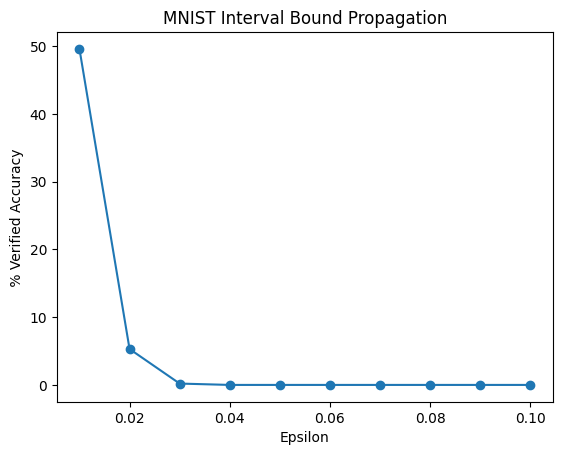

In [11]:
plt.plot(epsilons, results, marker="o")
plt.xlabel("Epsilon")
plt.ylabel(" % Verified Accuracy ")
plt.title("MNIST Interval Bound Propagation")
plt.show()